In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set the default Seaborn theme
sns.set_theme(style="ticks")

# Load the dataset and parse dates
df = pd.read_csv("../data_jobs.csv", parse_dates=["job_posted_date"])

# Convert string representations of lists into actual Python lists
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

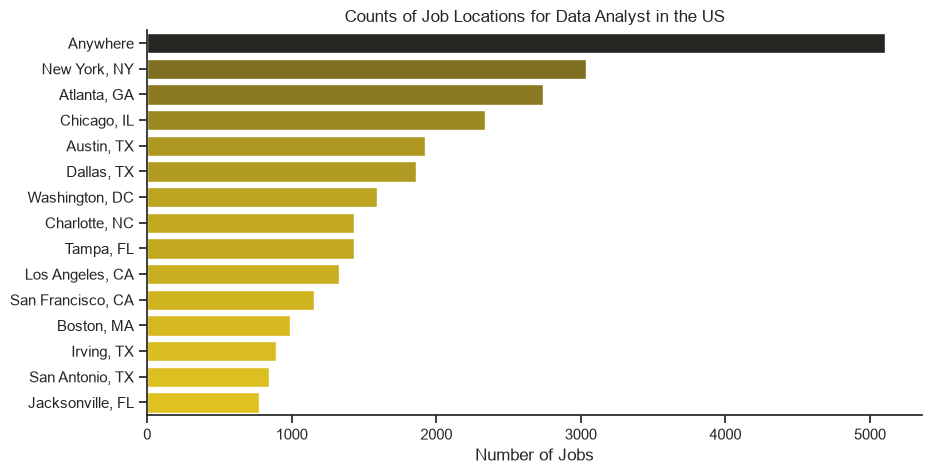

In [7]:
# Filter Data Analyst jobs in the United States
df_DA_US = df[
    (df["job_title_short"] == "Data Analyst") & (df["job_country"] == "United States")
]

# Get the 15 most common job locations
job_location = df_DA_US["job_location"].value_counts().head(15).reset_index()

plt.figure(figsize=(10, 5))

# Plot job counts by location
sns.barplot(
    data=job_location,
    x="count",
    y="job_location",
    hue='count', 
    palette='dark:gold_r',
    legend=False
)

plt.ylabel('')
plt.xlabel("Number of Jobs")
plt.title('Counts of Job Locations for Data Analyst in the US')
sns.despine()  # Remove the top and right spine
plt.show()

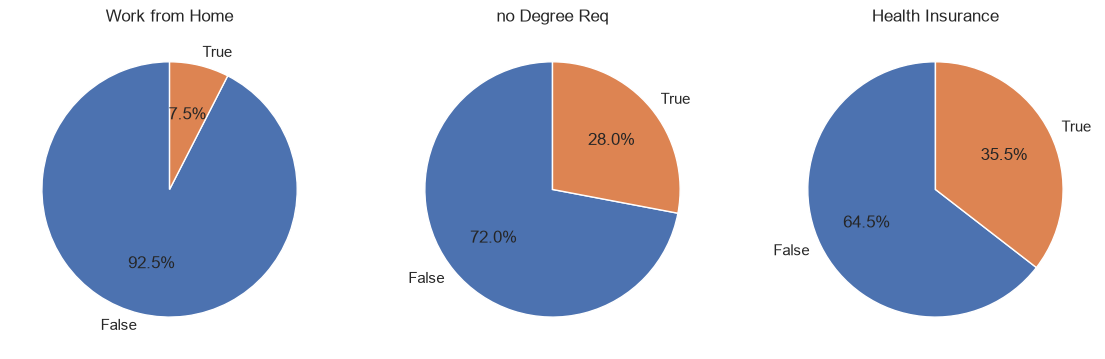

In [4]:
# Define columns and their corresponding titles
columns = ["job_work_from_home", "job_no_degree_mention", "job_health_insurance"]
titles = ['Work from Home', 'no Degree Req', 'Health Insurance']

# Create a figure with three subplots
fig, ax = plt.subplots(1, 3)

# Plot a pie chart for each column
for i in range(3):
    (
        df_DA_US[columns[i]]
        .value_counts()
        .plot(
                kind='pie',
                ax=ax[i],
                title=titles[i],
                startangle=90,
                autopct='%1.1f%%',
                figsize=(14, 10),
            )
    )

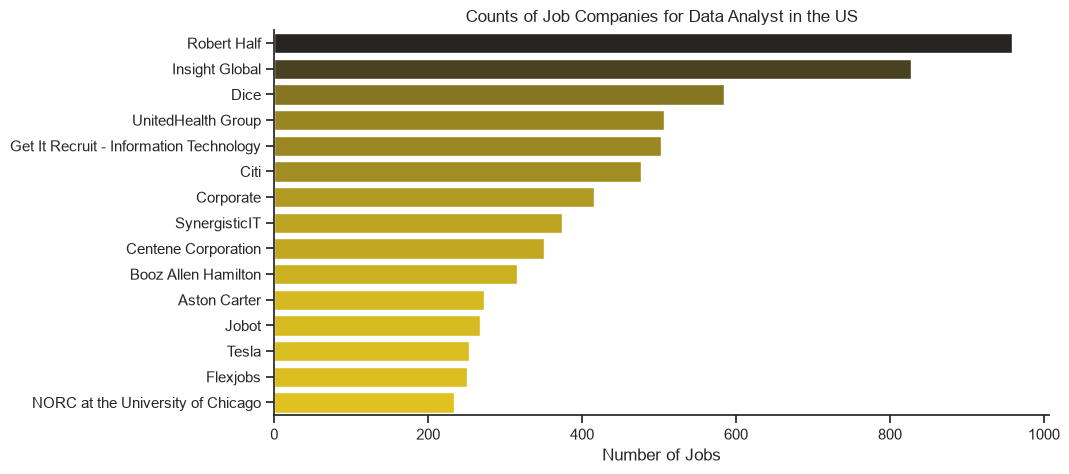

In [10]:
# Get the 15 companies with the most Data Analyst job postings
company_name = df_DA_US["company_name"].value_counts().head(15).reset_index()

plt.figure(figsize=(10, 5))

# Plot job counts by company
sns.barplot(
    data=company_name,
    x="count",
    y="company_name",
    hue="count",
    palette="dark:gold_r",
    legend=False,
)

sns.despine()
plt.ylabel("")
plt.xlabel("Number of Jobs")
plt.title("Counts of Job Companies for Data Analyst in the US")
plt.show()